In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Risk_Models.Factor_Risk_Model import risk
from Portfolio_Tracking.Risk_Model_Harness import multiple_model_tracker,run_multiple_risk_models

# from alpha_model import alpha_model
# from portfolio_optimizer import portfolio_optimization
# from clean_data import create_risk_factors,calculate_risk_factor_returns
# from analytics import portfolio_tracker, portfolio_metrics

%load_ext autoreload
%autoreload 2

In [2]:
sheet_data=[]
file_name="Data/SP500_2016-2025.xlsx"
df=pd.read_excel(file_name)
df['Sector'] = (df['GISC Code']//10000).astype("Int64")
df['Industry'] = (df['GISC Code']//1000000).astype("Int64")
df.head()

,Unnamed: 0,Date,Last Weekday,Last Sunday,Last Month End,Next Month End,Last Month Weekday,Next Month Weekday,Ticker,BBG Ticker,...,1 Month Momentum,12-1 Month Momentum,3 Month Momentum,1M EST EPS Revision,GISC Code,Market Beta 1 Year,Market Beta 5 Year,PCT_Return,Sector,Industry
0,0,2016-01-31,2016-01-29,2016-01-31 00:00:00,2015-12-31,2016-02-29 00:00:00,2015-12-31,2016-02-29 00:00:00,1436513D,1436513D US Equity,...,-0.114758,-0.138239,-0.192117,-0.042017,NaN,1.162727,1.365939,0.016448,<NA>,<NA>
1,343,2016-01-31,2016-01-29,2016-01-31 00:00:00,2015-12-31,2016-02-29 00:00:00,2015-12-31,2016-02-29 00:00:00,NUE,NUE US Equity,...,-0.034832,-0.074320,-0.076578,0.305382,55103010.0,0.679151,0.710357,0.006911,5510,55
2,342,2016-01-31,2016-01-29,2016-01-31 00:00:00,2015-12-31,2016-02-29 00:00:00,2015-12-31,2016-02-29 00:00:00,NTRS,NTRS US Equity,...,-0.156292,0.108049,-0.125880,0.054939,50203010.0,1.076654,1.052836,-0.043492,5020,50
3,341,2016-01-31,2016-01-29,2016-01-31 00:00:00,2015-12-31,2016-02-29 00:00:00,2015-12-31,2016-02-29 00:00:00,NTAP,NTAP US Equity,...,-0.184152,-0.293747,-0.350415,-0.003675,10102040.0,1.141177,0.908169,0.132695,1010,10
4,340,2016-01-31,2016-01-29,2016-01-31 00:00:00,2015-12-31,2016-02-29 00:00:00,2015-12-31,2016-02-29 00:00:00,NSC,NSC US Equity,...,-0.176017,-0.175643,-0.130596,0.020197,20201080.0,0.967810,0.981219,0.037872,2020,20


# Risk Model

In [3]:
def remove_problematic_tickers(data,max_zero_fill=10,required_universe_size=400):
    working_df=data.pivot(index="Date",columns="Ticker",values="PCT_Return")
    threshold = len(working_df) - max_zero_fill
    working_df = working_df.dropna(axis=1, thresh=threshold)
    valid_tickers=working_df.columns.to_list()
    valid_data=data[data["Ticker"].isin(valid_tickers)]
    if len(valid_tickers)<required_universe_size:
        raise ValueError(f"Universe must contain {required_universe_size} tickers got {len(valid_tickers)}")
    return valid_data, valid_tickers

def create_random_portfolio(n_assets,current_data):
    portfolio=current_data[["Date","Ticker","PCT_Return"]]
    hypothetical_weight=np.random.rand(len(current_data))
    selected_weight = np.zeros_like(hypothetical_weight)
    idx = np.random.choice(len(hypothetical_weight), size=n_assets, replace=False)
    selected_weight[idx] = hypothetical_weight[idx]
    portfolio["Weight"]=selected_weight/selected_weight.sum()
    
    individual_return=portfolio["Weight"]*portfolio["PCT_Return"]
    realized_return=float(individual_return.sum())
    portfolio.drop("Weight",axis=1)
    return portfolio, realized_return

In [4]:
all_dates=df["Date"].unique()

In [16]:
models_dict={"Basic model":risk(),
            "Ledoit-wolf model":risk(ledoit_wolf=True),
            "Fundamental factor model":risk(fundamental_factor_model=True,identity_covariance=True),
            "Fundamental factor model 1 month halflife":risk(fundamental_factor_model=True,identity_covariance=True,factor_ewma_halflife=1),
            "Fundamental factor model 2 month halflife":risk(fundamental_factor_model=True,identity_covariance=True,factor_ewma_halflife=2),
            "Fundamental factor model 3 month halflife":risk(fundamental_factor_model=True,identity_covariance=True,factor_ewma_halflife=3),
            "Fundamental factor model 4 month halflife":risk(fundamental_factor_model=True,identity_covariance=True,factor_ewma_halflife=4),
            "Fundamental factor model 5 month halflife":risk(fundamental_factor_model=True,identity_covariance=True,factor_ewma_halflife=5),
            "Fundamental factor model 6 month halflife":risk(fundamental_factor_model=True,identity_covariance=True,factor_ewma_halflife=6),
}



n_assets=[200,100,50,20,10] #number of assets in each random portfolio
trackers={n:multiple_model_tracker(models_dict) for n in n_assets}

seed_number=1
lookback=60
for i, date in enumerate(all_dates):
    print(f"\r{date}", end="", flush=True)
    if i<lookback:
        continue

    # Select historical PIT data 
    historical_data=df[(df["Date"]<date) & (df["Date"]>=all_dates[i-lookback])]
    historical_data,valid_tickers=remove_problematic_tickers(historical_data)
    average_return=historical_data.pivot(index="Date",columns="Ticker",values="PCT_Return").mean()
    average_return.name="AVG_Return"
    
    # Run risk models on historical data
    models_dict=run_multiple_risk_models(models_dict,historical_data)

    # Identify current data
    current_data=df[df["Date"]==date]
    current_data=current_data[current_data["Ticker"].isin(valid_tickers)]

    
    for n in n_assets:
        #Create a random diversified portfolio
        np.random.seed(seed_number);seed_number+=1
        portfolio,realized_return=create_random_portfolio(n,current_data)

        
        excess_portfolio=portfolio[["Ticker","Weight","PCT_Return"]].merge(average_return,on="Ticker",how="left")
        excess_portfolio["Excess_return"]=excess_portfolio["PCT_Return"]-excess_portfolio["AVG_Return"]
        excess_return=(excess_portfolio["Excess_return"]*excess_portfolio["Weight"]).sum()

        # Update tracking
        trackers[n].append_multiple_variance_estimates(date,models_dict,current_data,portfolio)
        trackers[n].append_multiple_realized_systematic_returns(date,models_dict,current_data,portfolio)
        trackers[n].append_realized_return(date,realized_return)
        trackers[n].append_excess_return(date,excess_return)
            


2025-12-31 00:00:00

In [17]:
for n in n_assets:
    print(f"Performance Summary for Portfolio with {n} Assets:")
    display(trackers[n].performance_summary(models_dict))
    print("\n")

Performance Summary for Portfolio with 200 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Z Excess Kurtosis
Basic model,-0.023332,0.840532,0.695263,-0.244539
Ledoit-wolf model,-0.026561,0.928114,0.847745,-0.203083
Fundamental factor model,-0.025512,0.837764,0.690803,-0.342907
Fundamental factor model 1 month halflife,-0.096058,1.193130,1.409060,0.436999
Fundamental factor model 2 month halflife,-0.061803,1.043823,1.075227,-0.165673
Fundamental factor model 3 month halflife,-0.057535,0.988533,0.964220,-0.100483
Fundamental factor model 4 month halflife,-0.054152,0.951910,0.893963,-0.090281
Fundamental factor model 5 month halflife,-0.050441,0.924891,0.843710,-0.124767
Fundamental factor model 6 month halflife,-0.047051,0.904579,0.806839,-0.169308




Performance Summary for Portfolio with 100 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Z Excess Kurtosis
Basic model,0.001209,0.866202,0.737803,-0.548667
Ledoit-wolf model,0.000619,0.954660,0.896187,-0.516697
Fundamental factor model,-0.004934,0.866286,0.737968,-0.586948
Fundamental factor model 1 month halflife,-0.083043,1.236021,1.509181,0.145990
Fundamental factor model 2 month halflife,-0.045478,1.081562,1.152347,-0.608056
Fundamental factor model 3 month halflife,-0.038442,1.022994,1.030553,-0.573287
Fundamental factor model 4 month halflife,-0.033822,0.985091,0.955374,-0.556707
Fundamental factor model 5 month halflife,-0.029701,0.957266,0.901967,-0.568718
Fundamental factor model 6 month halflife,-0.026239,0.936273,0.862686,-0.587503




Performance Summary for Portfolio with 50 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Z Excess Kurtosis
Basic model,0.003778,0.844862,0.701910,-0.223255
Ledoit-wolf model,0.003170,0.928343,0.847467,-0.176348
Fundamental factor model,0.000473,0.845568,0.703068,-0.210742
Fundamental factor model 1 month halflife,-0.079699,1.157281,1.323329,0.582862
Fundamental factor model 2 month halflife,-0.036463,1.033359,1.051363,-0.156251
Fundamental factor model 3 month halflife,-0.027213,0.983730,0.952336,-0.071245
Fundamental factor model 4 month halflife,-0.022084,0.950040,0.888022,-0.030623
Fundamental factor model 5 month halflife,-0.018036,0.924892,0.841493,-0.042923
Fundamental factor model 6 month halflife,-0.014859,0.905818,0.807052,-0.074201




Performance Summary for Portfolio with 20 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Z Excess Kurtosis
Basic model,-0.025146,0.809414,0.644865,-0.526454
Ledoit-wolf model,-0.028670,0.878243,0.759277,-0.506332
Fundamental factor model,-0.036817,0.790024,0.615092,-0.557662
Fundamental factor model 1 month halflife,-0.103266,1.032204,1.058352,-0.497851
Fundamental factor model 2 month halflife,-0.078248,0.949922,0.893436,-0.529177
Fundamental factor model 3 month halflife,-0.069847,0.907047,0.813901,-0.489744
Fundamental factor model 4 month halflife,-0.063707,0.877360,0.760990,-0.471712
Fundamental factor model 5 month halflife,-0.058687,0.855874,0.723757,-0.465462
Fundamental factor model 6 month halflife,-0.054719,0.840025,0.696876,-0.465257




Performance Summary for Portfolio with 10 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Z Excess Kurtosis
Basic model,0.020576,0.866211,0.738240,-0.248996
Ledoit-wolf model,0.022546,0.925814,0.843354,-0.238183
Fundamental factor model,0.023844,0.834667,0.685627,-0.274724
Fundamental factor model 1 month halflife,-0.014574,0.944992,0.878338,-0.453165
Fundamental factor model 2 month halflife,-0.003007,0.915800,0.824720,-0.336753
Fundamental factor model 3 month halflife,0.000023,0.901163,0.798559,-0.258907
Fundamental factor model 4 month halflife,0.002409,0.887787,0.775036,-0.232898
Fundamental factor model 5 month halflife,0.004641,0.875818,0.754294,-0.233719
Fundamental factor model 6 month halflife,0.006579,0.865696,0.736983,-0.243896


In [ ]:
def plot_volatility_estimates(tracker,models_dict,number_of_assets):
    vol_cloud=[]
    for i,model in enumerate(models_dict):
        vol=pd.DataFrame(tracker.variance_estimates[model]).iloc[0]
        vol.name=model
        vol_cloud.append(vol)
    vol_cloud=pd.concat(vol_cloud,axis=1)
    cmap = plt.colormaps['tab20']
    plt.figure(figsize=(15, 9))
    colors = [cmap(i / (len(models_dict)+1 - 1)) for i in range(len(models_dict)+1)]
    for i,col in enumerate(vol_cloud):
        plt.plot(vol_cloud[col],color=colors[i],label=col,marker='o')
    plt.plot(pd.DataFrame(tracker.realized_returns).iloc[0]**2,color=colors[i+1],label="Realized Return",marker='o')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title(f"Variance Estimates for Portfolio with {number_of_assets} Assets")
    plt.tight_layout()
    plt.show()

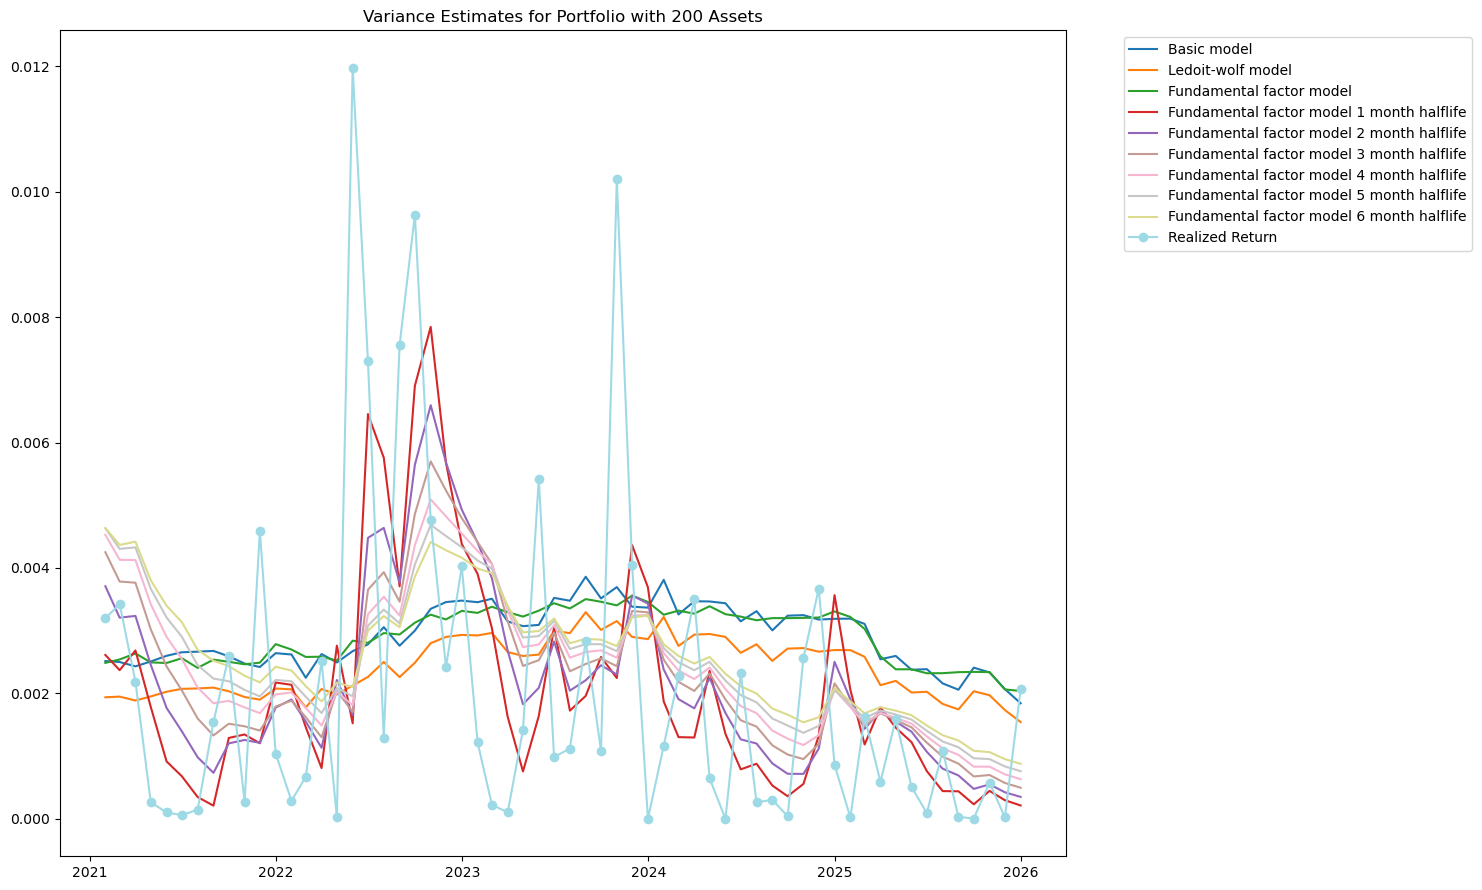

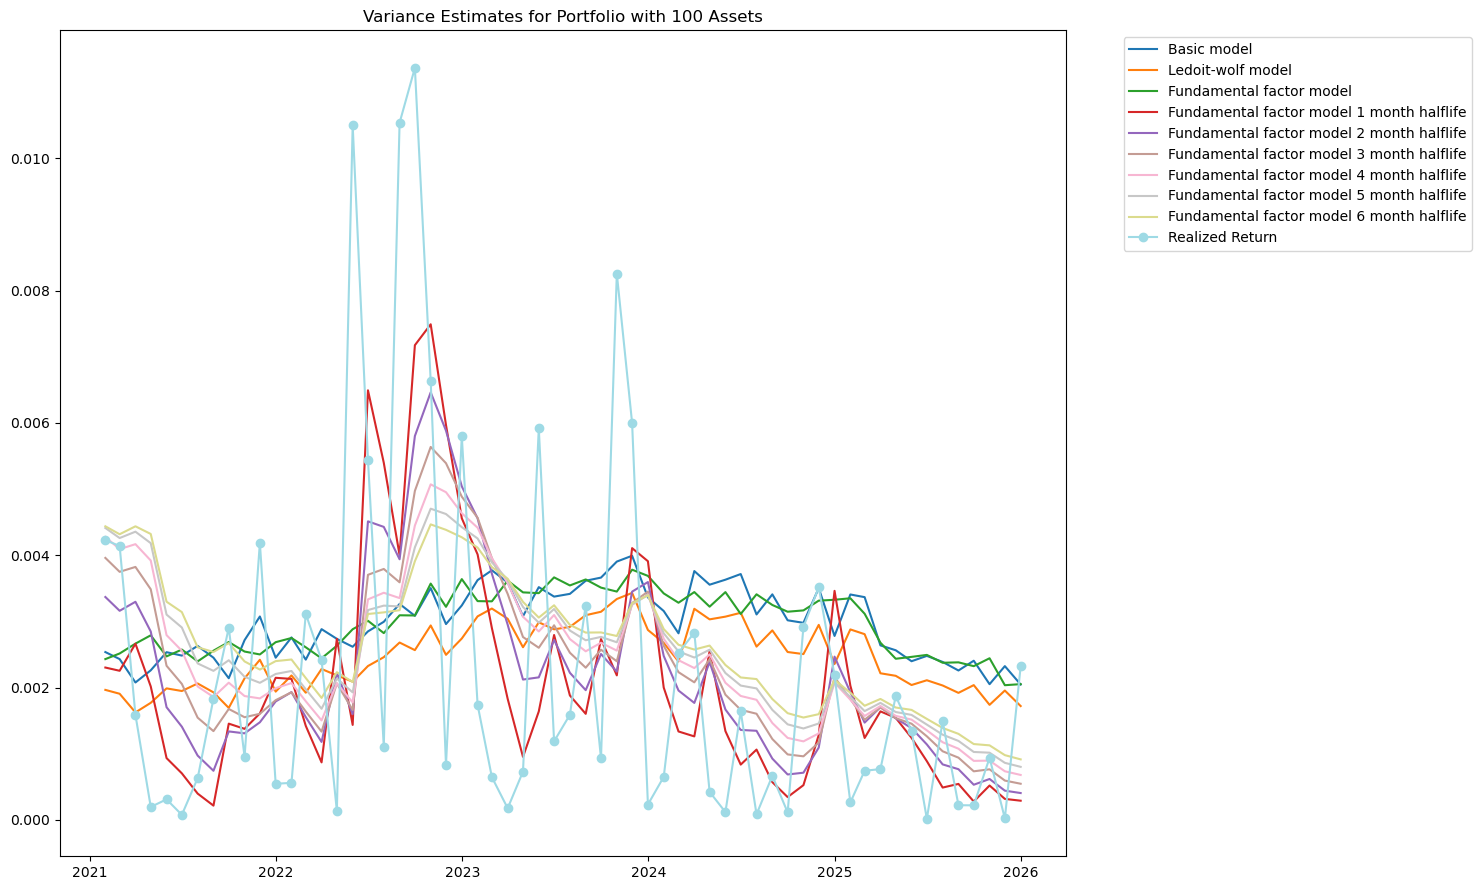

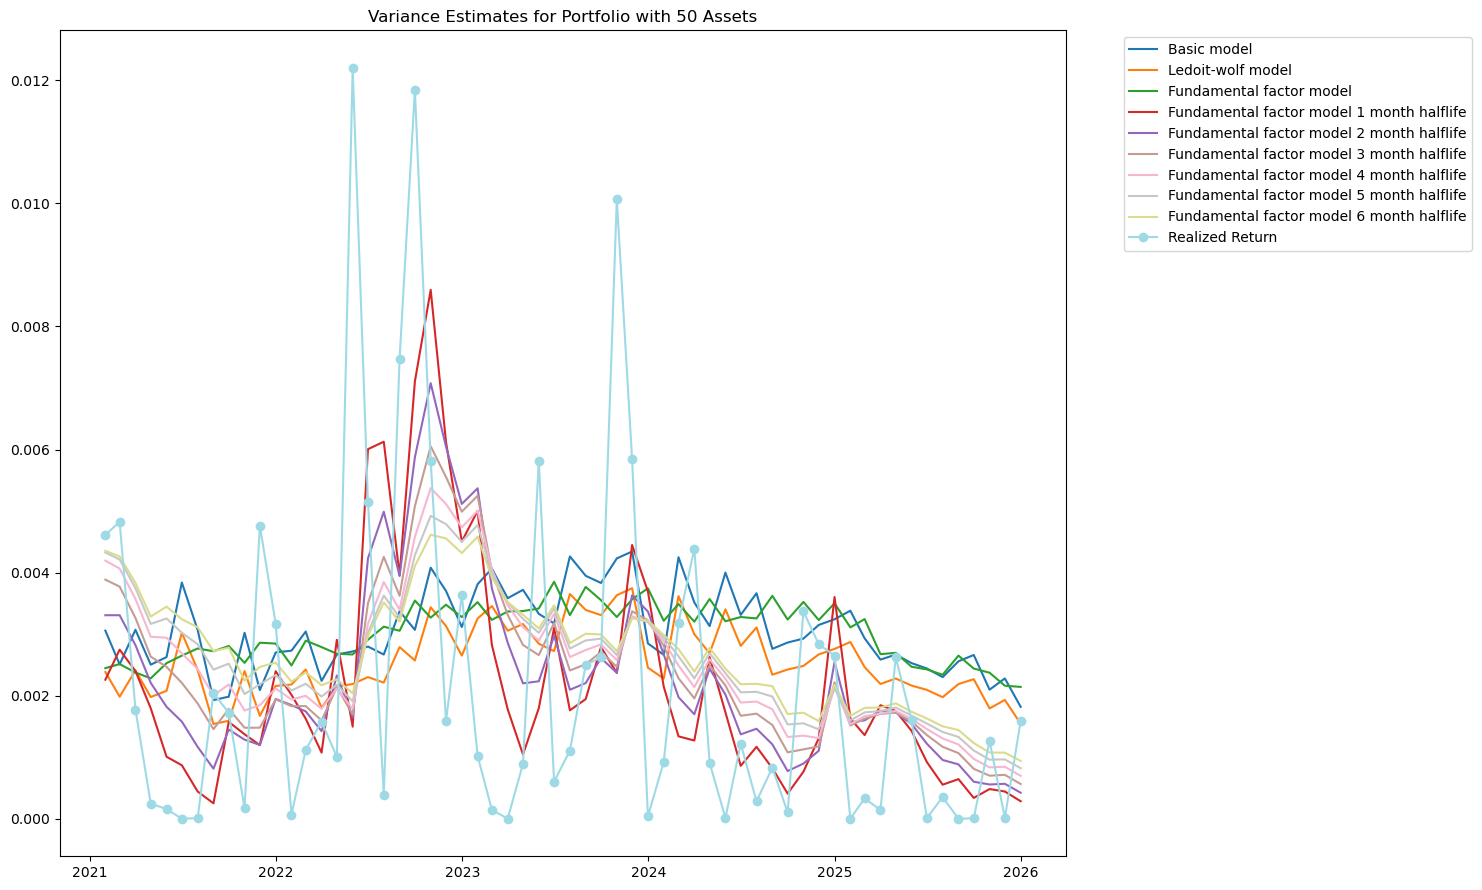

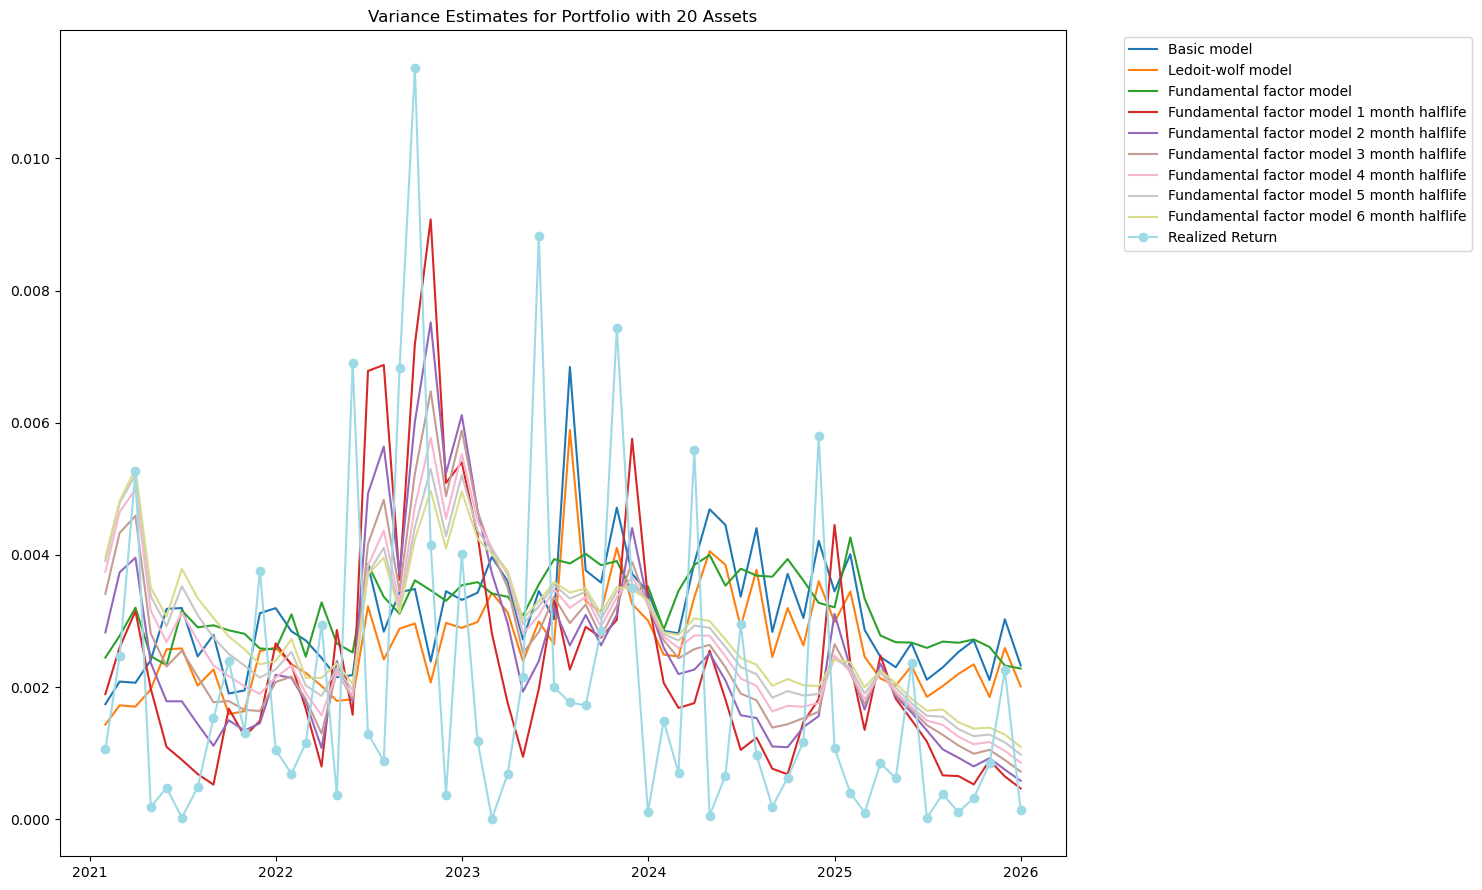

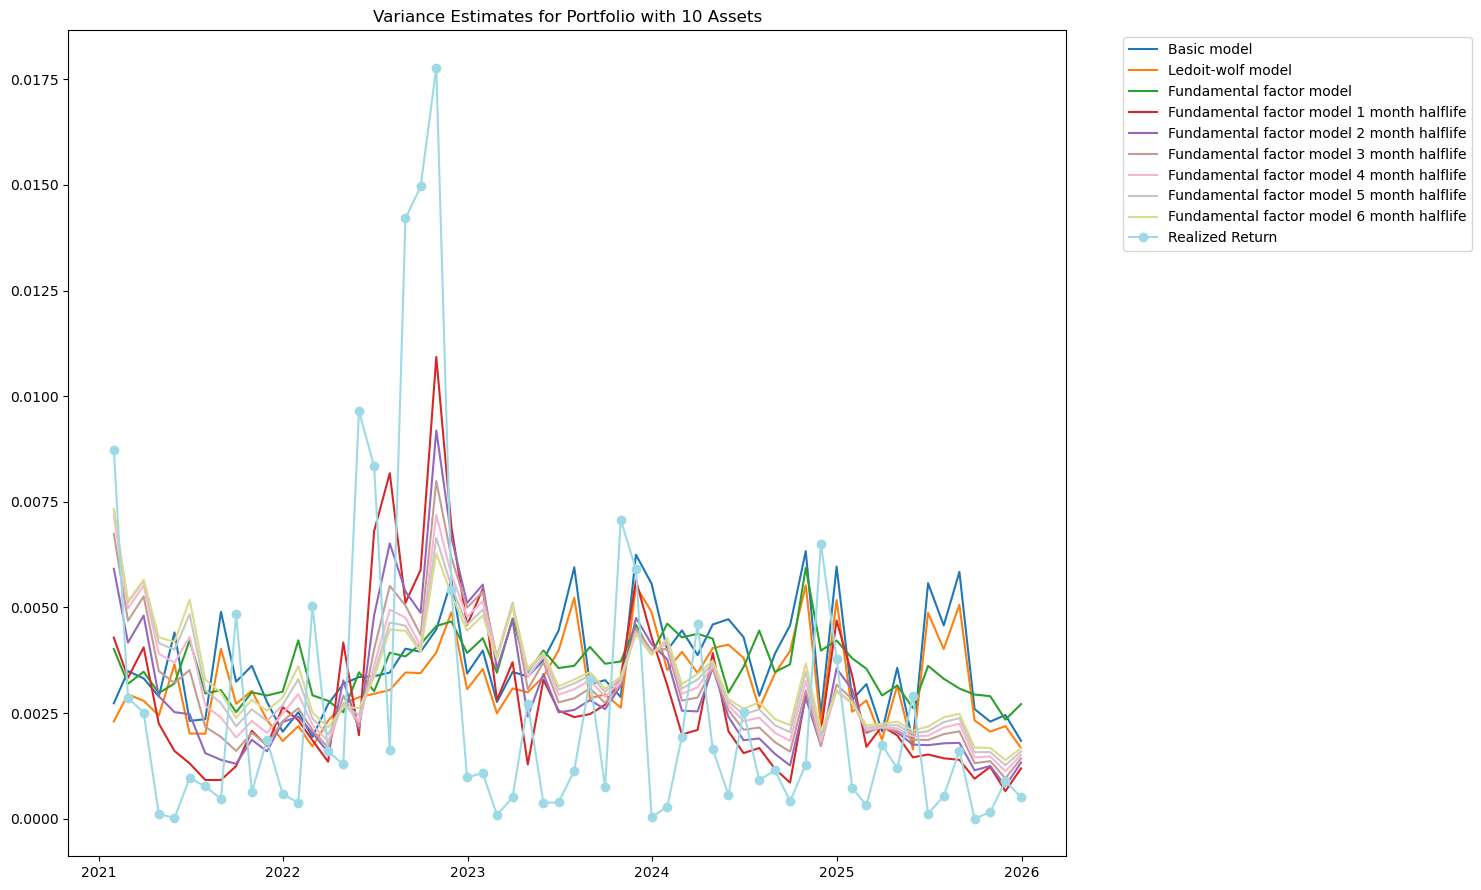

In [32]:
for n in n_assets:
    plot_volatility_estimates(trackers[n],models_dict,n)
    print("\n")